Exploratory Data Analysis
==========================

1.  Data Overview  - look at the below attributes of data to understad it  better.
    No of Files, no of columns, content, rows, basic summary of columns (descriptive stats of numeric and categorical columns)

2. Univarient Analysis - analyze signe column, it's frequency distribution using count plot (categorical col), histogram, boxplot of numerical column (quintiles, mean, outliers), outliars and missing data (why we have missing data and what can we do. If column is removed , will it be concern ? or can I remove rows .)

Working with missing data can add errors in your analysis
ex Failed delivery will not have a delivery date so if data is missing in delivery date then it's not a concern and see if we need failed delivery for our analysis otherwise filter those or handle differently
3. Data Imputation  - Deriving missing values from same column whereever values are not missing or from other columns.Eg - age is missing, get the avg age of the customer to add if acceptable, and no DOB in database.
Mean - for numericals columns but affacted by outliars
Meadian - not affected by outliars
Mode - Categorical column 

4. Bivarient or Multivarient  - 2 or more variables analysed simultaneousely 
If both are numerical - Scatterplot 
one Num and other timebased - Line chart
one Num and other col is categorical - Bar chart or Categorical Box plot
Both col are categorical - then Heatmap or stacked bar chart

5. for Many - Co-relation heat map , -1 to +1 values to show the relationship strength/intensity and are 2 variables are lineraly related or not
-ve co-relations is, if one increases and other decreases , while +ve co-relation is if one increases then other also increases.

In analysis report, what to describe in initial report :
=====================================
what was given to you.
Data decripency issues that were found
Uneful insights 
Data chellanges




In [6]:
import sys
print(sys.version)
print(sys.executable)
%pip install pandas==2.2.3 matplotlib==3.9.4 seaborn==0.13.2


3.9.6 (default, Oct  4 2024, 08:01:31) 
[Clang 16.0.0 (clang-1600.0.26.4)]
/Library/Developer/CommandLineTools/usr/bin/python3
Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 7.8 MB 462 kB/s eta 0:00:01
     |████████████████████████████████| 294 kB 2.8 MB/s eta 0:00:01
     |████████████████████████████████| 126 kB 9.5 MB/s eta 0:00:01
     |████████████████████████████████| 2.9 MB 6.7 MB/s eta 0:00:01
     |████████████████████████████████| 64 kB 5.8 MB/s eta 0:00:01
     |████████████████████████████████| 4.7 MB 9.9 MB/s eta 0:00:01
     |████████████████████████████████| 249 kB 5.7 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [7]:
%pip install --upgrade pip

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 1.8 MB 1.0 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip --version

pip 26.0.1 from /Users/rachanachoudhary/Library/Python/3.9/lib/python/site-packages/pip (python 3.9)
Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda x: f'{x:.3f}')

**Data Overview**
1) Check for row counts, column counts, and samples
2) Data Quality Checks: Missing Values, Duplicates, Data Types
3) Descriptive Statistics

Load both of the files in pandas df and confirm they have loaded correctly by printing shape

In [7]:
df_subscribers = pd.read_csv("/Users/rachanachoudhary/Downloads/streamwave-churn-analysis/subscribers.csv")
print(f"df_subscribers : {df_subscribers.shape}")

df_watch_history = pd.read_csv("/Users/rachanachoudhary/Downloads/streamwave-churn-analysis/watch_history.csv")
print(f"df_watch_history : {df_watch_history.shape}")

df_subscribers : (10000, 15)
df_watch_history : (306935, 11)


1) Printing row count, column count, and a representative sample of the data for each dataset.

In [10]:
# Storing both dataframes in a dictionary for iterating
dataframes = {
    "df_subscribers": df_subscribers,
    "df_watch_history": df_watch_history
}

# Display row count, column count, and first 5 rows for each
for name, df in dataframes.items():
    print(f"\n--- {name} ---")
    print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
    display(df.head())


--- df_subscribers ---
Rows: 10000, Columns: 15


,subscriber_id,account_id,age,gender,region,country,signup_date,current_plan,signup_channel,device_primary,household_size,churn_status,churn_date,price_increase_flag,is_resub
0,SUB_000001,ACC_000001,44.000,Male,North America,CA,2022-12-15,Standard,Referral,Mobile,1.000,0,NaN,0,0
1,SUB_000002,ACC_000002,NaN,Male,Western Europe,DE,2026-01-30,Basic-Ads,Free Trial,Mobile,2.000,1,2026-02-21,1,0
2,SUB_000003,ACC_000003,32.000,Female,North America,US,2024-02-25,Premium,Paid Social,TV,4.000,0,NaN,0,0
3,SUB_000004,ACC_000004,33.000,Male,North America,US,2024-06-24,Basic-Ads,Paid Social,TV,2.000,1,2026-01-13,1,0
4,SUB_000005,ACC_000005,32.000,Undisclosed,North America,US,2025-11-28,Basic-Ads,Paid Social,TV,NaN,1,2026-02-28,0,0



--- df_watch_history ---
Rows: 306935, Columns: 11


,session_id,subscriber_id,session_date,content_id,content_category,content_length_minutes,watch_duration_minutes,completion_pct,device_used,time_of_day,engagement_score
0,SES_00000001,SUB_000001,2025-08-13,CNT_00945,Licensed Movies,107,106,0.993,Mobile,Morning,50.348
1,SES_00000002,SUB_000001,2026-02-20,CNT_21098,Live Sports,120,71,0.599,Mobile,Evening,50.348
2,SES_00000003,SUB_000001,2025-04-22,CNT_49631,Ad-Supported Catalog,43,37,0.865,Mobile,Evening,50.348
3,SES_00000004,SUB_000001,2025-08-02,CNT_34829,Originals,50,30,0.614,Mobile,Evening,50.348
4,SES_00000005,SUB_000001,2025-04-05,CNT_23324,Ad-Supported Catalog,46,34,0.744,Mobile,Evening,50.348


2) Data Quality Checks: Missing Values, Duplicates, Data Types

For each dataset, checking for the presence of missing values, duplicate values, and data type issues. If present, highlighting where they occur.

In [11]:
# Check missing values, duplicates, and data types for each dataset
for name, df in dataframes.items():
    print(f"\n---- Data Quality Check for {name} ----")

    # Missing values as a rounded percentage
    print("Missing Values (%):\n", round(df.isnull().sum() / df.isnull().count() * 100, 3))

    # Duplicate rows count
    print(f"\nDuplicate rows: {df.duplicated().sum()}")

    # Data types
    print(f"\nData Types:\n {df.dtypes}")


---- Data Quality Check for df_subscribers ----
Missing Values (%):
 subscriber_id          0.000
account_id             0.000
age                    2.790
gender                 4.490
region                 0.000
country                0.000
signup_date            0.000
current_plan           0.000
signup_channel         0.000
device_primary         1.970
household_size        12.220
churn_status           0.000
churn_date            64.990
price_increase_flag    0.000
is_resub               0.000
dtype: float64

Duplicate rows: 0

Data Types:
 subscriber_id           object
account_id              object
age                    float64
gender                  object
region                  object
country                 object
signup_date             object
current_plan            object
signup_channel          object
device_primary          object
household_size         float64
churn_status             int64
churn_date              object
price_increase_flag      int64
is_resub     

What we identified after above Data Quality Checks:
The churn_date column is missing for ~65% of rows. This is expected because a null churn date simply means the subscriber has not churned (i.e., they are still retained).
Other missing values are smaller: household_size (12.22%), gender (4.49%), age (2.79%), and device_primary (1.97%). These missing values will not be imputed for this analysis as I am keeping imputation out of scope as of now.
No duplicate rows in either dataset.
All date columns are stored as plain text and need to be converted to datetime format.

3) Descriptive Statistics

In [17]:
# Generate descriptive statistics for both datasets
for name, df in dataframes.items():
    print(f"\n--- Descriptive Statistics for {name} ---")
    #print(df.describe)
    display(df.describe(include='all'))



--- Descriptive Statistics for df_subscribers ---


,subscriber_id,account_id,age,gender,region,country,signup_date,current_plan,signup_channel,device_primary,household_size,churn_status,churn_date,price_increase_flag,is_resub
count,10000,10000,9721.000,9551,10000,10000,10000,10000,10000,9803,8778.000,10000.000,3501,10000.000,10000.000
unique,10000,9434,NaN,4,2,8,1448,3,6,4,NaN,NaN,366,NaN,NaN
top,SUB_000001,ACC_000100,NaN,Female,North America,US,2026-01-08,Basic-Ads,Free Trial,TV,NaN,NaN,2026-03-30,NaN,NaN
freq,1,3,NaN,4264,5996,4978,30,4846,2287,4790,NaN,NaN,35,NaN,NaN
mean,NaN,NaN,40.184,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.416,0.350,NaN,0.218,0.062
std,NaN,NaN,13.907,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.316,0.477,NaN,0.413,0.241
min,NaN,NaN,18.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000,0.000,NaN,0.000,0.000
25%,NaN,NaN,29.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000,0.000,NaN,0.000,0.000
50%,NaN,NaN,39.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000,0.000,NaN,0.000,0.000
75%,NaN,NaN,51.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000,1.000,NaN,0.000,0.000



--- Descriptive Statistics for df_watch_history ---


,session_id,subscriber_id,session_date,content_id,content_category,content_length_minutes,watch_duration_minutes,completion_pct,device_used,time_of_day,engagement_score
count,306935,306935,306935,306935,306935,306935.000,306935.000,306935.000,301907,306935,306935.000
unique,306935,9865,366,49896,5,NaN,NaN,NaN,4,4,NaN
top,SES_00000001,SUB_006173,2026-02-28,CNT_09035,Licensed Movies,NaN,NaN,NaN,TV,Evening,NaN
freq,1,100,986,18,96917,NaN,NaN,NaN,148854,153458,NaN
mean,NaN,NaN,NaN,NaN,NaN,74.577,48.861,0.662,NaN,NaN,52.425
std,NaN,NaN,NaN,NaN,NaN,38.115,30.160,0.198,NaN,NaN,19.923
min,NaN,NaN,NaN,NaN,NaN,15.000,0.000,0.050,NaN,NaN,0.000
25%,NaN,NaN,NaN,NaN,NaN,45.000,26.000,0.536,NaN,NaN,36.922
50%,NaN,NaN,NaN,NaN,NaN,60.000,41.000,0.693,NaN,NaN,52.913
75%,NaN,NaN,NaN,NaN,NaN,105.000,68.000,0.816,NaN,NaN,70.219


from descriptive statistics below are the findings :

Subscribers (10,000 records)

Age ranges 18-70 (mean ~40, std ~14). North America dominates (5,996 of 10,000); US is the top country.
Basic-Ads is the most common plan (~4,846). Free Trial is the top acquisition channel (2,287).
TV is the primary device (4,790 of 9,803 with data). Average household size is ~2.4.
Churn rate is 35%. Only 6.2% are re-subscribers. 21.8% experienced a price increase.
Watch History (306,935 sessions)

9,865 unique subscribers have watch activity, meaning ~135 subscribers have no sessions at all.
These 135 subscribers will be excluded from further analysis, as the reason for having no recorded sessions is unknown, whether due to lack of engagement or missing/untracked activity.
Licensed Movies dominate content (96,917 sessions). Evening is peak viewing time (153,458 sessions).
Average content length is ~75 min; average watch duration is ~49 min (about 66% completion on average).
Engagement score ranges from 0 to 98.3.

**Data Preprocessing**
1) Parse Data Types : Date columns are currently stored as plain text, which prevents any time-based computations. Let's convert all date-like columns across both datasets to proper datetime format.

In [ ]:
# Convert date columns in df_subscribers
# errors='coerce' sets invalid entries to NaT
df_subscribers['signup_date'] = pd.to_datetime(df_subscribers['signup_date'], errors='coerce')
df_subscribers['churn_date'] = pd.to_datetime(df_subscribers['churn_date'], errors='coerce')

# Convert date columns in df_watch_history
df_watch_history['session_date'] = pd.to_datetime(df_watch_history['session_date'], errors='coerce')

# Verify converted data types
print("df_subscribers date columns:")
print(df_subscribers[['signup_date', 'churn_date']].dtypes)
print("\ndf_watch_history date column:")
print(df_watch_history['session_date'].dtypes)

**Exploratory Data Analysis**
Univariate Analysis
Q1: Which acquisition channels are driving the highest volume of our subscriber base?
Q2: What is the distribution of subscribers across our pricing tiers?
Q3: How are subscriber engagement levels distributed across the user base?

Bivariate Analysis
Q1: Is there a measurable difference in engagement levels based on acquisition channel?
Q2: Is there a measurable difference in engagement levels based on subscription plan?
Q3: Is lack of engagement a behavioral divider between retained and churned users?

Multivariate Analysis
Q1: Does a user's engagement level override the churn risk of their signup channel?
Q2: To what extent does high engagement shield the platform against the friction of ad-supported or premium-priced tiers?


Q1: Which acquisition channels are driving the highest volume of our subscriber base?

Visualize the distribution of subscribers across different signup channels using a bar chart, sorted by the highest volume to the lowest.

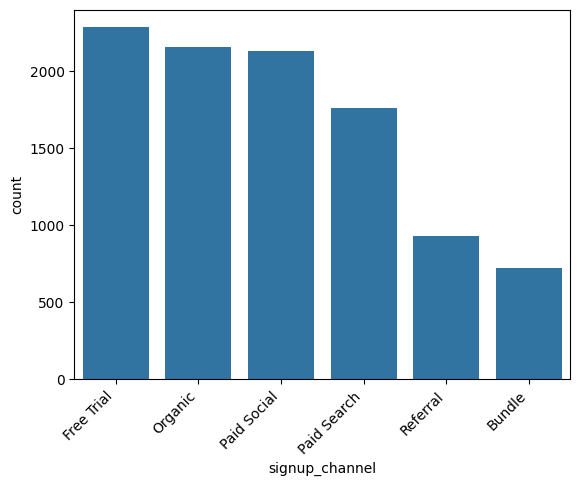

In [34]:
# Count plot of subscribers by signup channel, sorted by volume
channel_order = df_subscribers['signup_channel'].value_counts().index
#print(channel_order)
sns.countplot(data=df_subscribers, x='signup_channel', order=channel_order)
plt.xticks(rotation=45, ha='right')
plt.show()


-->Free Trial is the largest acquisition channel (~2,300 subscribers), followed by Organic (~2,160) and Paid Social (~2,130).
-->Referral (~930) and Bundle (~725) generate the lowest signup volume.


Q2: What is the distribution of subscribers across our pricing tiers?

Visualize the total number of subscribers across each current subscription plan using a bar chart.


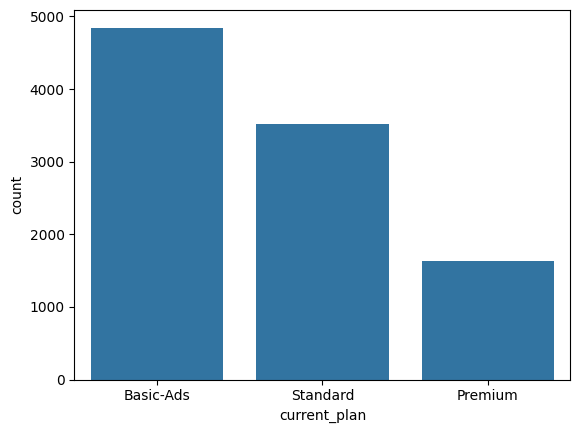

In [38]:
# Count plot of subscribers by subscription plan
current_plan_order = df_subscribers['current_plan'].value_counts().index
sns.countplot(data=df_subscribers, x='current_plan', order=current_plan_order)
plt.show()

The majority of subscribers are on the Basic-Ads plan.
As plan pricing increases, the number of subscribers decreases, which is expected.

Q3: How are subscriber engagement levels distributed across the user base?
An active subscription does not guarantee actual platform usage. The engagement score distribution reveals whether the bulk of the user base is highly engaged, casually watching, or acting as "zombie" accounts at high risk of passive churn.

Visualize the distribution of the engagement score using a histogram to understand the overall activity levels of our subscriber base.

Since a subscriber may have multiple watch sessions, we aggregate the engagement score by taking the mean across all sessions to get a single subscriber-level metric.

In [ ]:
# Summarize engagement score per subscriber (mean across all sessions)
subscriber_engagement = df_watch_history.groupby('subscriber_id')['engagement_score'].mean().reset_index()
#print(subscriber_engagement)

# Merge subscriber-level engagement into the subscribers dataframe
merged_df = pd.merge(df_subscribers, subscriber_engagement, on='subscriber_id', how='left').reset_index()
#print(merged_df)



     subscriber_id  engagement_score
0       SUB_000001            50.348
1       SUB_000002             0.125
2       SUB_000003            49.480
3       SUB_000004            27.054
4       SUB_000005            38.751
...            ...               ...
9860    SUB_009996            78.514
9861    SUB_009997            18.108
9862    SUB_009998            50.960
9863    SUB_009999            37.835
9864    SUB_010000            57.534

[9865 rows x 2 columns]
      index subscriber_id  account_id    age       gender          region  \
0         0    SUB_000001  ACC_000001 44.000         Male   North America   
1         1    SUB_000002  ACC_000002    NaN         Male  Western Europe   
2         2    SUB_000003  ACC_000003 32.000       Female   North America   
3         3    SUB_000004  ACC_000004 33.000         Male   North America   
4         4    SUB_000005  ACC_000005 32.000  Undisclosed   North America   
...     ...           ...         ...    ...          ...            